# 033 — CatBoost com ponderação intermédia

Compara `alpha = 0`, `0.25` e `0.5` em pesos `frequência**(-alpha)`, normalizados para média 1 e calculados exclusivamente nos rótulos do treino interno. `alpha=0` é o controlo sem pesos e `alpha=0.5` reproduz a política do 031. Mantêm-se parâmetros CatBoost, limites de memória, uma thread, limite de 1.000 iterações, early stopping 50 e semente 42 do 031. A seleção é feita por Macro F1 não ponderada do sklearn nas 16 classes; a métrica interna CatBoost é verificada.

Usa a preparação central e divisão estratificada fixa já existentes. Nenhuma estatística ou categoria é aprendida juntando treino, validação e teste; `AGE_RANGE`, `PID`, `HHID`, `PROXY` e `COUNTRY` não são features. A validação fixa é desenvolvimento, não teste independente. Kaggle não participa da seleção e fica em branco. Executar sequencialmente; o checkpoint valida dados, preparação, código, parâmetros e versões.

Reconstrução do controlo: a execução armazenada do 031 selecionou `inverse_sqrt` em 376 iterações; o runner 029 original não está presente. As versões do ambiente atual são as mesmas registadas para 031/032; a versão do 029 histórico não está disponível. `used_ram_limit=512mb` controla CTRs e não limita a memória total do processo; nenhuma restrição foi alterada.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'src' / 'experiments_033_034.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Executa este notebook na pasta notebooks/ deste projeto.')
sys.path.insert(0, str(root))
from src.experiments_033_034 import run_033, _package_versions

result = run_033()
display(pd.DataFrame([{
    'alpha': row['alpha'],
    'iterações': row['selected_iterations'],
    'Macro F1 interna sklearn': row['sklearn_macro_f1'],
    'Macro F1 CatBoost': row['catboost_macro_f1'],
    'tempo seleção (s)': row['fit_seconds'],
} for row in result['internal_candidates']]))
print('Selecionado exclusivamente na validação interna:', result['selected_internally']['alpha'])
print('Configuração:', result['configuration'])
print('Versões do ambiente:', _package_versions())
print('Tempo de treino (s):', result['training_seconds'], '| tempo total (s):', result['wall_seconds'])

033: resultado reutilizado após validar dados, preparação, código, parâmetros e versões.


,alpha,iterações,Macro F1 interna sklearn,Macro F1 CatBoost,tempo seleção (s)
0,0.00,181,0.462479,0.462479,124.594066
1,0.25,286,0.460595,0.460595,177.851637
2,0.50,376,0.488735,0.488735,228.989966


Selecionado exclusivamente na validação interna: 0.5
Configuração: {'control_031': {'depth': 4, 'learning_rate': 0.1, 'selected_029_iterations': 262, 'max_iterations': 1000, 'early_stopping_rounds': 50, 'resource_parameters': {'boosting_type': 'Plain', 'max_ctr_complexity': 1, 'ctr_leaf_count_limit': 256, 'border_count': 32, 'one_hot_max_size': 10, 'counter_calc_method': 'SkipTest', 'rsm': 0.2, 'leaf_estimation_iterations': 1, 'used_ram_limit': '512mb'}, 'thread_count': 1, 'control_031_weighted_selected_iterations': 376}, 'alphas': [0.0, 0.25, 0.5], 'weight_formula': 'freq^-alpha normalized to arithmetic mean 1 using fit labels only', 'selection_metric': 'sklearn Macro F1, labels 0..15, unweighted', 'seed': 42, 'outer_split': {'test_size': 0.2, 'random_state': 42, 'stratified': True}, 'inner_split': {'test_size': 0.15, 'random_state': 42, 'stratified': True}}
Versões do ambiente: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'catb

In [2]:
fixed = result['fixed_metrics']
print('Treino 8.769 linhas:', {k: fixed['train'][k] for k in ('macro_f1', 'accuracy')})
print('Validação fixa:', {k: fixed['validation'][k] for k in ('macro_f1', 'accuracy')})
class_metrics = pd.DataFrame(fixed['validation']['per_class'])
class_metrics['destacada'] = class_metrics['classe'].map({1: 'CHAVE', 6: 'CHAVE', 13: 'CHAVE'}).fillna('')
display(class_metrics[['classe', 'escalão', 'F1', 'recall', 'support', 'destacada']])
print('Kaggle score: — (não submetido)')
print('Submissão:', result['submission'])
print('Diferenças face aos CSVs anteriores:', result['submission']['differences'])

Treino 8.769 linhas: {'macro_f1': 0.6239535032003067, 'accuracy': 0.6101037746607367}
Validação fixa: {'macro_f1': 0.4586573739052191, 'accuracy': 0.45690834473324216}


,classe,escalão,F1,recall,support,destacada
0,0,15–17 anos,0.800000,0.878049,41,
1,1,18–19 anos,0.542857,0.558824,34,CHAVE
2,2,20–24 anos,0.601307,0.575000,80,
3,3,25–29 anos,0.318471,0.333333,75,
4,4,30–34 anos,0.266667,0.266667,90,
5,5,35–39 anos,0.369565,0.395349,129,
6,6,40–44 anos,0.375796,0.343023,172,CHAVE
7,7,45–49 anos,0.368254,0.335260,173,
8,8,50–54 anos,0.643038,0.701657,181,
9,9,55–59 anos,0.625616,0.625616,203,


Kaggle score: — (não submetido)
Submissão: {'path': None, 'duplicate_of': ['submission_031_catboost_ponderacao_suave.csv'], 'differences': {'submission_001_regressao_logistica.csv': 1686, 'submission_002_regressao_logistica_regularizada.csv': 1441, 'submission_004_arvore_decisao.csv': 2148, 'submission_007_xgboost.csv': 1286, 'submission_010_mlp_pytorch.csv': 1601, 'submission_012_mlp_perda_ponderada.csv': 1606, 'submission_014_xgboost_mlp.csv': 1205, 'submission_015_mlp_learning_rate.csv': 1483, 'submission_016_xgboost_mlp015.csv': 1194, 'submission_017_mlp_ponderacao_suave.csv': 1424, 'submission_018_mlp_sgd.csv': 1481, 'submission_019_ensemble_pesos.csv': 1196, 'submission_020_mlp_dropout.csv': 1425, 'submission_021_mlp_sgd_ponderacao_suave.csv': 1426, 'submission_025_xgboost_mlp_dropout.csv': 1175, 'submission_028_ensemble_features_dominio.csv': 1181, 'submission_029_catboost.csv': 695, 'submission_031_catboost_ponderacao_suave.csv': 0}, 'reason': 'As previsões reproduzem um CSV an

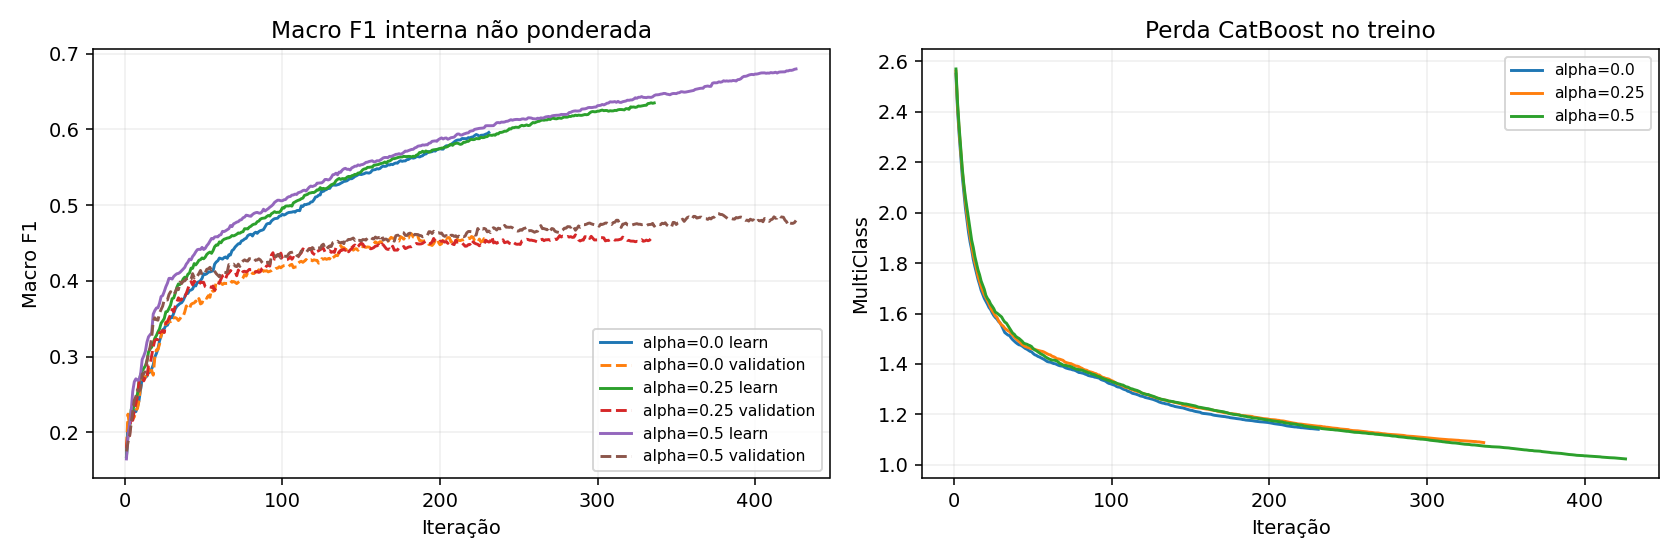

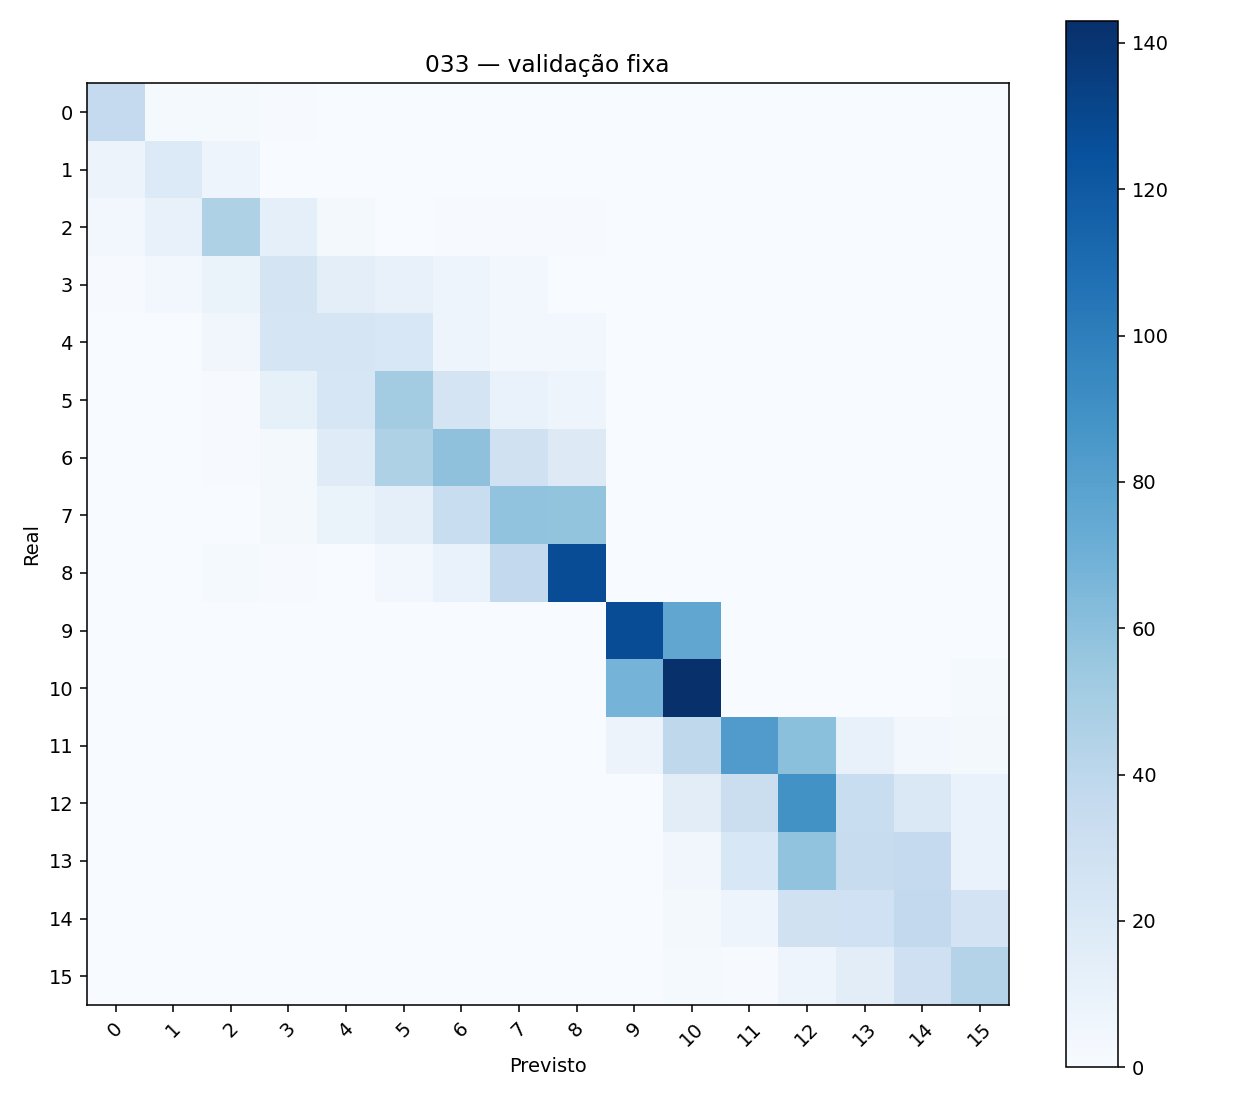

In [3]:
display(Image(filename=str(root / result['curves'])))
display(Image(filename=str(root / result['confusion_matrix'])))

## Conclusão
- Data: 16/11

- A escolha de `alpha` vem apenas da Macro F1 interna não ponderada. A avaliação fixa e as diferenças entre CSVs são diagnósticas, não alteram a escolha. A submissão só é guardada quando as previsões são distintas dos CSVs anteriores; se ficar abaixo dos controlos, é exploratória e não recomendada para ocupar uma submissão.